# Model Deployment: GAN on MNIST

In [1]:
import math

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

torch.manual_seed(42)

device = (
    torch.device("mps")
    if torch.backends.mps.is_available()
    else torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
)
print(f"Using device: {device}")

Using device: mps


## model.py

In [2]:
NOISE_DIM = 100


class Generator(nn.Module):
    def __init__(self, noise_dim=NOISE_DIM):
        super().__init__()
        self.fc = nn.Linear(noise_dim, 7 * 7 * 128)
        self.net = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, kernel_size=4, stride=2, padding=1),
            nn.Tanh(),
        )

    def forward(self, z):
        x = self.fc(z)
        x = x.view(-1, 128, 7, 7)
        return self.net(x)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
        )
        self.fc = nn.Linear(128 * 7 * 7, 1)

    def forward(self, x):
        x = self.net(x)
        x = x.view(x.size(0), -1)
        return torch.sigmoid(self.fc(x))


def get_model(model_name):
    if model_name == "GAN":
        model = (Generator(), Discriminator())
    else:
        raise ValueError(f"Unknown model: {model_name}")
    return model

## trainer.py

In [3]:
def train_gan(model, data_loader, criterion, optimizer, device='cpu', epochs=10):
    # model is the (generator, discriminator) pair, optimizer is (opt_G, opt_D)
    G, D = model
    opt_G, opt_D = optimizer
    G.to(device).train()
    D.to(device).train()

    for epoch in range(epochs):
        for real, _ in data_loader:
            real = real.to(device)
            bs = real.size(0)
            real_labels = torch.ones(bs, 1, device=device)
            fake_labels = torch.zeros(bs, 1, device=device)

            # Train discriminator
            z = torch.randn(bs, NOISE_DIM, device=device)
            fake = G(z)
            loss_D = criterion(D(real), real_labels) + criterion(D(fake.detach()), fake_labels)
            opt_D.zero_grad()
            loss_D.backward()
            opt_D.step()

            # Train generator
            loss_G = criterion(D(fake), real_labels)
            opt_G.zero_grad()
            loss_G.backward()
            opt_G.step()

        print(f"Epoch {epoch+1}/{epochs}  D loss: {loss_D.item():.4f}  G loss: {loss_G.item():.4f}")

    return model

## generator.py

In [4]:
def generate_samples(model, device, num_samples=10):
    model.to(device).eval()
    with torch.no_grad():
        z = torch.randn(num_samples, NOISE_DIM, device=device)
        images = model(z).cpu()
    images = (images + 1) / 2  # [-1, 1] -> [0, 1]

    cols = min(num_samples, 5)
    rows = math.ceil(num_samples / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2, rows * 2), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, img in zip(axes.flat, images):
        ax.imshow(img.squeeze(), cmap='gray')
    plt.show()

## Train on MNIST

In [5]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

train_dataset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, drop_last=True)

In [6]:
G, D = get_model("GAN")

criterion = nn.BCELoss()
opt_G = optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_D = optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))

G, D = train_gan((G, D), train_loader, criterion, (opt_G, opt_D), device=device, epochs=20)

Epoch 1/20  D loss: 0.3922  G loss: 1.0075


Epoch 2/20  D loss: 0.2596  G loss: 2.9977


Epoch 3/20  D loss: 0.3402  G loss: 1.8833


Epoch 4/20  D loss: 0.2609  G loss: 2.5198


Epoch 5/20  D loss: 0.3269  G loss: 2.3736


...

Epoch 16/20  D loss: 0.1129  G loss: 4.5918


Epoch 17/20  D loss: 0.3648  G loss: 5.9922


Epoch 18/20  D loss: 0.1108  G loss: 5.3042


Epoch 19/20  D loss: 0.2464  G loss: 4.4873


Epoch 20/20  D loss: 0.1574  G loss: 4.9569


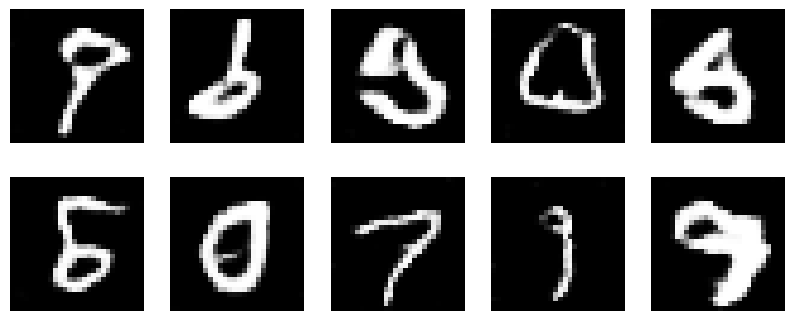

In [7]:
generate_samples(G, device, num_samples=10)

## Save the generator for the API

In [8]:
torch.save(G.state_dict(), "gentext-app/app/gan_mnist.pt")